### 1. Imports & Telco Customer Churn Dataset Loading
* **Libraries & Pipeline Setup:** Imported core data manipulation (`pandas`, `numpy`), Scikit-Learn preprocessing/validation (`ColumnTransformer`, `OneHotEncoder`, `StandardScaler`, `SimpleImputer`, `train_test_split`, `GridSearchCV`, `StratifiedKFold`), `imblearn` (`Pipeline`, `SMOTE`), tree ensemble classifiers (`RandomForestClassifier`, `XGBClassifier`), evaluation metrics, and plotting libraries (`matplotlib`, `seaborn`).
* **Dataset Ingestion:** Loaded the Telco Customer Churn dataset (`Telco-Customer-Churn.csv`) containing customer demographics, tenure, subscription/add-on services (`PhoneService`, `InternetService`, `OnlineSecurity`, `DeviceProtection`, `TechSupport`), billing details, and churn status (`customerID` rows visible in preview).

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split,GridSearchCV,StratifiedKFold
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score,roc_curve,accuracy_score,precision_score,recall_score,f1_score
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2. Exploratory Data Analysis & TotalCharges Type Conversion
* **Dataset Structure & Missingness:** Inspected `df.info()`, missing value counts, and descriptive statistics across 7,043 records and 21 columns, noting that `TotalCharges` initially appeared as non-null string entries before numeric casting[cite: 12, 13].
* **Numeric Coercion:** Converted `TotalCharges` to a numeric column using `pd.to_numeric(..., errors="coerce")` so blank/invalid strings become `NaN` values for proper pipeline imputation[cite: 13].

In [3]:
print("BASIC INSIGHTS OF DATASET:-\n")
print("Information of Dataset\n")
print(df.info())
print("\n")
print("Missing Values:-\n")
print(df.isnull().sum())
print("\n")
print("Statistical Insights:-\n")
print(df.describe())

BASIC INSIGHTS OF DATASET:-

Information of Dataset

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  

In [11]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

### 3. Train-Test Split & Leak-Free Preprocessing Pipelines
* **Stratified Split & Feature Grouping:** Mapped `Churn` (`Yes` to 1, `No` to 0), dropped `Churn` and `customerID`, performed an 80/20 stratified train-test split (`random_state=42`), and separated numeric (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`) from categorical features[cite: 13, 14].
* **Modular Transformers & SMOTE:** Built a `ColumnTransformer` applying mean imputation and `StandardScaler` to numeric columns alongside most-frequent imputation and `OneHotEncoder(handle_unknown="ignore")` to categorical columns, wrapped inside `ImbPipeline` with `SMOTE` so oversampling happens strictly inside training folds[cite: 14].

In [4]:
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn", "customerID"])

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

# 2. Preprocessing transformer
numeric_pipe = ImbPipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),])

categorical_pipe = ImbPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numerical_cols),
    ("cat", categorical_pipe, categorical_cols),])

# 3. Full pipeline with SMOTE inside CV folds
rf_pipeline = ImbPipeline([
    ("prep", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1)),])

xgb_pipeline = ImbPipeline([
    ("prep", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model",XGBClassifier(random_state=42,eval_metric="logloss",n_jobs=-1,),),])

### 4. Hyperparameter Tuning & Cross-Validation (`GridSearchCV`)
* **Search Setup:** Configured `GridSearchCV` with `scoring="roc_auc"`, `n_jobs=-1`, and `StratifiedKFold` (`n_splits=2`, `shuffle=True`, `random_state=42`) across candidate grids for `RandomForestClassifier` (24 candidates) and `XGBClassifier` (48 candidates) inside their SMOTE pipelines.
* **Best CV Results:** Random Forest reached a best CV ROC-AUC of **0.8354** (`max_depth=None`, `min_samples_leaf=1`, `min_samples_split=10`, `n_estimators=200`), while XGBoost achieved a higher best CV ROC-AUC of **0.8475** (`colsample_bytree=0.8`, `learning_rate=0.08`, `max_depth=3`, `n_estimators=200`, `subsample=1.0`).

In [5]:
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

rf_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [8, 12, None],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 4],}

xgb_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.08],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1,)

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1,)

rf_grid.fit(X_train, y_train)
xgb_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_
best_xgb = xgb_grid.best_estimator_

print(f"Best RF CV ROC-AUC:  {rf_grid.best_score_:.4f}")
print(f"Best RF Params:      {rf_grid.best_params_}\n")
print(f"Best XGB CV ROC-AUC: {xgb_grid.best_score_:.4f}")
print(f"Best XGB Params:     {xgb_grid.best_params_}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best RF CV ROC-AUC:  0.8354
Best RF Params:      {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10, 'model__n_estimators': 200}

Best XGB CV ROC-AUC: 0.8475
Best XGB Params:     {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.08, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 1.0}


### 5. Test Set Evaluation & Confusion Matrix Comparison
* **ROC-AUC & Metrics:** Evaluated both tuned models on the held-out test set (1,409 records: 1,035 non-churners and 374 churners)[cite: 17, 18]. XGBoost (SMOTE) achieved a test ROC-AUC of **0.8439**, accuracy of **0.7757**, churn recall of **0.6979**, and churn F1-score of **0.6229**, compared to Random Forest (SMOTE) with a test ROC-AUC of **0.8263**, accuracy of **0.7771**, churn recall of **0.5775**, and churn F1-score of **0.5791**.
* **Confusion Matrix Trade-Off:** XGBoost captured more actual churners (261 true positives vs. 113 false negatives) than Random Forest (216 true positives vs. 158 false negatives), whereas Random Forest had fewer false positives on non-churners (156 vs. 203).

=== Random Forest (SMOTE) ===
Test ROC-AUC : 0.8263
Accuracy     : 0.7771
Precision    : 0.5806
Recall       : 0.5775
F1-Score     : 0.5791

              precision    recall  f1-score   support

          No       0.85      0.85      0.85      1035
         Yes       0.58      0.58      0.58       374

    accuracy                           0.78      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.78      0.78      0.78      1409

=== XGBoost (SMOTE) ===
Test ROC-AUC : 0.8439
Accuracy     : 0.7757
Precision    : 0.5625
Recall       : 0.6979
F1-Score     : 0.6229

              precision    recall  f1-score   support

          No       0.88      0.80      0.84      1035
         Yes       0.56      0.70      0.62       374

    accuracy                           0.78      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.78      0.78      1409



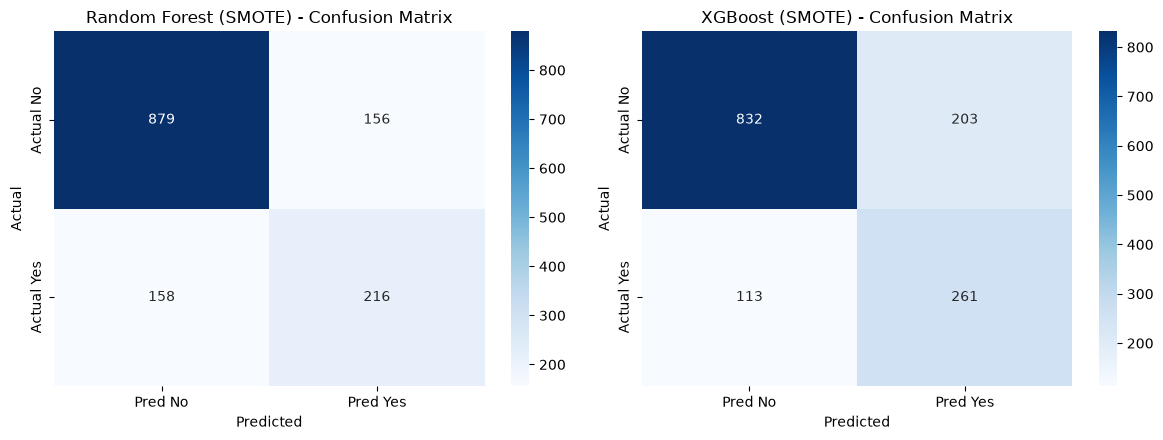

In [9]:
models = {"Random Forest (SMOTE)": best_rf,
    "XGBoost (SMOTE)": best_xgb}

test_probs = {}
test_preds = {}

for name, model in models.items():
  y_prob = model.predict_proba(X_test)[:, 1]
  y_pred = model.predict(X_test)
  test_probs[name] = y_prob
  test_preds[name] = y_pred

  auc = roc_auc_score(y_test, y_prob)
  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)

  print(f"=== {name} ===")
  print(f"Test ROC-AUC : {auc:.4f}")
  print(f"Accuracy     : {acc:.4f}")
  print(f"Precision    : {prec:.4f}")
  print(f"Recall       : {rec:.4f}")
  print(f"F1-Score     : {f1:.4f}\n")
  print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))

# Side-by-side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, y_pred) in zip(axes, test_preds.items()):
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      ax=ax,
      xticklabels=["Pred No", "Pred Yes"],
      yticklabels=["Actual No", "Actual Yes"],
  )
  ax.set_title(f"{name} - Confusion Matrix")
  ax.set_ylabel("Actual")
  ax.set_xlabel("Predicted")
plt.tight_layout()
plt.show()

### 6. ROC-AUC Curve & Top 10 Feature Importances
* **ROC-AUC Curve Comparison:** Plotted False Positive Rate against True Positive Rate for both models against the 0.5000 random-guess baseline, showing XGBoost (SMOTE) achieving **0.8439** AUC ahead of Random Forest (SMOTE) at **0.8263**.
* **Top 10 Most Influential Features (XGBoost):** Extracted transformed feature names from the fitted preprocessor and ranked XGBoost feature importances, highlighting `cat_Contract_Month-to-month` as the top churn driver followed by `cat_TechSupport_No`, `cat_OnlineSecurity_No`, `cat_InternetService_Fiber optic`, and `cat_PaymentMethod_Electronic check`.

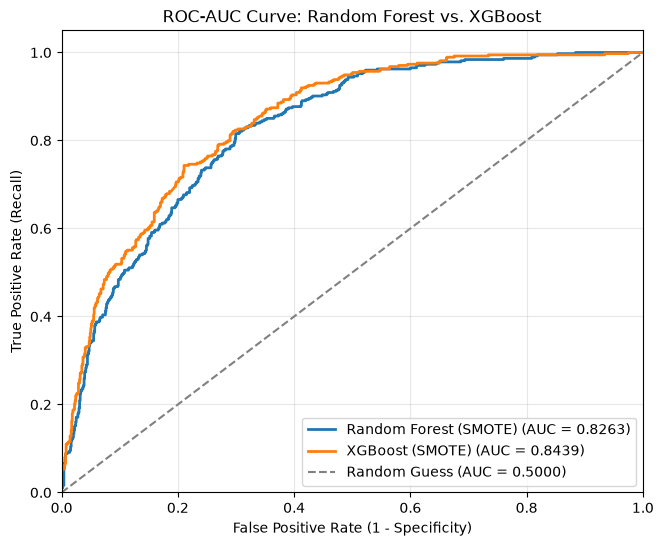

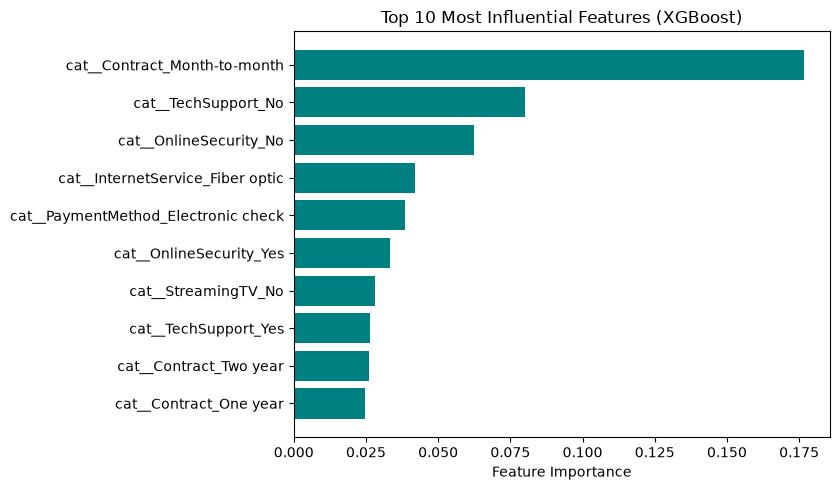

In [10]:
# ROC-AUC Comparison Curve
plt.figure(figsize=(7.5, 6))
for name, y_prob in test_probs.items():
  fpr, tpr, _ = roc_curve(y_test, y_prob)
  auc = roc_auc_score(y_test, y_prob)
  plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.4f})")

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Guess (AUC = 0.5000)",
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-AUC Curve: Random Forest vs. XGBoost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# Top 10 Feature Importances (using best XGBoost model; swap to best_rf if preferred)
fitted_prep = best_xgb.named_steps["prep"]
feature_names = fitted_prep.get_feature_names_out()
importances = best_xgb.named_steps["model"].feature_importances_

top10_df = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(10)
    .iloc[::-1]
)

plt.figure(figsize=(8.5, 5))
plt.barh(top10_df["feature"], top10_df["importance"], color="teal")
plt.xlabel("Feature Importance")
plt.title("Top 10 Most Influential Features (XGBoost)")
plt.tight_layout()
plt.show()

### 7. Conclusion & Key Takeaways
* **Benchmark Achieved:** Both SMOTE-augmented ensemble classifiers surpassed the 0.80 test ROC-AUC target on the Telco Customer Churn dataset, with **XGBoost (0.8439)** outperforming **Random Forest (0.8263)** in ranking customers by churn risk.
* **Model Selection Trade-Off:** XGBoost delivered stronger churn detection (`Recall = 0.6979`, `F1 = 0.6229`, catching 261 of 374 actual churners), making it better suited for proactive retention campaigns where missing a churner is costly, whereas Random Forest achieved slightly higher overall accuracy (`0.7771` vs. `0.7757`) and fewer false positives on non-churners (156 vs. 203).
* **Actionable Business Drivers:** Month-to-month contracts, absence of tech support or online security add-ons, fiber optic internet service, and electronic check payments emerged as the strongest predictors of customer churn, pointing retention efforts toward longer-term contract incentives and bundled support/security features.
* **Leak-Free Pipeline Integrity:** Coercing `TotalCharges` to numeric and placing imputation, encoding, and SMOTE strictly inside cross-validated pipelines ensured reliable, leakage-free evaluation across all deliverables (ROC curve, confusion matrices, and Top 10 feature importances).